In [31]:
# importing packages
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import scipy as sp
import seaborn as sn
import warnings
warnings.simplefilter("ignore")

I'm curious how the minimum variance and maximum Sharpe ratio portfolios, discussed in 00, move over time.

In [32]:
symbols = ['XDWT.DE', 'XDWI.DE', 'XDW0.DE', 'XDWH.DE', 'XDWF.DE', 'XDWC.DE', 'XWTS.DE', 'XDWS.DE'] # Sector ETFs from Xtrackers
n = len(symbols)
for symbol in symbols:
    info = yf.Ticker(symbol).info
    print(f"{symbol}: {info.get('longName', 'N/A')}")

datasets = {}
years = [2018, 2019, 2020, 2021, 2022, 2023, 2024]
for year in years:
    raw_data = yf.download(symbols, start = f'{year}-01-01')
    data = raw_data['Close']
    datasets[year] = data
    print(data.head())

XDWT.DE: Xtrackers MSCI World Information Technology UCITS ETF 1C
XDWI.DE: Xtrackers MSCI World Industrials UCITS ETF 1C
XDW0.DE: Xtrackers MSCI World Energy UCITS ETF 1C
XDWH.DE: Xtrackers MSCI World Health Care UCITS ETF 1C
XDWF.DE: Xtrackers MSCI World Financials UCITS ETF 1C
XDWC.DE: Xtrackers MSCI World Consumer Discretionary UCITS ETF 1C
XWTS.DE: Xtrackers MSCI World Communication Services UCITS ETF 1C
XDWS.DE: Xtrackers MSCI World Consumer Staples UCITS ETF 1C


[*********************100%***********************]  8 of 8 completed


Ticker        XDW0.DE    XDWC.DE    XDWF.DE  XDWH.DE    XDWI.DE    XDWS.DE  \
Date                                                                         
2018-01-02  28.514999  25.745001  16.454000   25.170  29.719999  28.545000   
2018-01-03  29.035000  25.985001  16.524000   25.395  30.000000  28.580000   
2018-01-04  29.225000  25.975000  16.688000   25.395  30.285000  28.540001   
2018-01-05  29.299999  26.280001  16.757999   25.660  30.530001  28.770000   
2018-01-08  29.465000  26.490000  16.858000   25.695  30.799999  28.865000   

Ticker        XDWT.DE  XWTS.DE  
Date                            
2018-01-02  21.219999   10.550  
2018-01-03  21.545000   10.506  
2018-01-04  21.670000   10.498  
2018-01-05  21.885000   10.562  
2018-01-08  22.125000   10.642  


[*********************100%***********************]  7 of 8 completed


Ticker        XDW0.DE    XDWC.DE  XDWF.DE    XDWH.DE    XDWI.DE    XDWS.DE  \
Date                                                                         
2019-01-02  25.645000  25.504999   14.442  26.809999  26.750000  27.084999   
2019-01-03  25.535000  25.184999   14.316  26.540001  26.325001  27.075001   
2019-01-04  26.075001  25.785000   14.638  27.010000  26.965000  27.395000   
2019-01-07  26.469999  26.245001   14.682  27.145000  27.155001  27.285000   
2019-01-08  26.625000  26.415001   14.662  27.075001  27.385000  27.385000   

Ticker        XDWT.DE  XWTS.DE  
Date                            
2019-01-02  21.639999   10.064  
2019-01-03  20.870001   10.060  
2019-01-04  21.325001   10.264  
2019-01-07  21.540001   10.344  
2019-01-08  21.610001   10.444  


...

Ticker        XDW0.DE    XDWC.DE    XDWF.DE    XDWH.DE    XDWI.DE    XDWS.DE  \
Date                                                                           
2022-01-03  27.985001  52.910000  22.815001  44.875000  44.639999  40.915001   
2022-01-04  28.764999  53.189999  23.370001  44.775002  45.345001  41.544998   
2022-01-05  29.209999  53.110001  23.375000  44.509998  45.465000  41.419998   
2022-01-06  29.305000  51.689999  23.254999  43.869999  44.845001  41.119999   
2022-01-07  29.620001  51.139999  23.495001  43.320000  44.595001  40.770000   

Ticker        XDWT.DE    XWTS.DE  
Date                              
2022-01-03  60.040001  18.094000  
2022-01-04  59.389999  18.049999  
2022-01-05  58.840000  17.912001  
2022-01-06  57.439999  17.726000  
2022-01-07  56.680000  17.520000  


[*********************100%***********************]  8 of 8 completed
[******************    38%                       ]  3 of 8 completed

Ticker        XDW0.DE    XDWC.DE    XDWF.DE    XDWH.DE    XDWI.DE    XDWS.DE  \
Date                                                                           
2023-01-02  43.380001  37.549999  21.995001  46.250000  41.939999  41.410000   
2023-01-03  42.334999  37.145000  21.945000  45.910000  41.770000  41.134998   
2023-01-04  41.560001  37.810001  22.334999  46.130001  42.055000  41.480000   
2023-01-05  42.165001  37.605000  22.184999  45.779999  41.900002  41.294998   
2023-01-06  43.005001  37.955002  22.405001  45.884998  42.474998  41.814999   

Ticker        XDWT.DE  XWTS.DE  
Date                            
2023-01-02  44.814999   12.324  
2023-01-03  43.840000   12.284  
2023-01-04  44.165001   12.490  
2023-01-05  43.705002   12.448  
2023-01-06  43.884998   12.510  


[*********************100%***********************]  8 of 8 completed

Ticker        XDW0.DE    XDWC.DE    XDWF.DE    XDWH.DE    XDWI.DE    XDWS.DE  \
Date                                                                           
2024-01-02  43.014999  47.985001  24.330000  46.480000  49.110001  40.855000   
2024-01-03  43.380001  47.290001  24.245001  46.755001  48.529999  41.029999   
2024-01-04  43.305000  47.075001  24.370001  47.095001  48.650002  40.875000   
2024-01-05  43.180000  46.855000  24.395000  46.860001  48.450001  40.680000   
2024-01-08  42.119999  47.125000  24.350000  46.830002  48.375000  40.709999   

Ticker        XDWT.DE    XWTS.DE  
Date                              
2024-01-02  63.980000  16.962000  
2024-01-03  63.340000  17.068001  
2024-01-04  62.980000  17.025999  
2024-01-05  62.990002  16.988001  
2024-01-08  63.730000  17.091999  


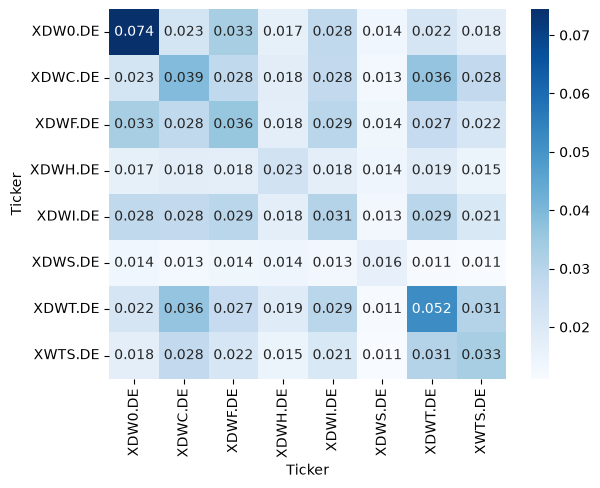

In [33]:
returns = {year: df.pct_change().dropna() for year, df in datasets.items()}
cov_matrix = {year: df.cov() * 252 for year, df in returns.items()} # Annualised
mean_returns = {year: df.mean() * 252 for year, df in returns.items()} # Annualised

sn.heatmap(cov_matrix[2018], annot=True, fmt='.3f', cmap='Blues')
plt.show()

In [45]:
random_weights = np.random.dirichlet(np.ones(n), size=500000).T # Dirichlet distribution to ensure weights sum to 1, while being random.

portfolio_returns = {year: random_weights.T @ mean_returns[year] for year, df in datasets.items()}
portfolio_variance = {year: np.einsum('ij,jk,ik->i', random_weights.T, cov_matrix[year], random_weights.T) for year, df in datasets.items()} # einsum for computation speed
portfolio_volatility = {year: np.sqrt(var) for year, var in portfolio_variance.items()}

In [46]:
rf = 0.0225 # ECB rate

wmv = {year: sp.optimize.minimize(lambda w: w.T @ cov_matrix[year] @ w, x0 = np.ones(n) / n, bounds=[(0, 1)] * n, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) for year in datasets}
wms = {year: sp.optimize.minimize(lambda w: -w.T @ (mean_returns[year] - rf) / (np.sqrt(w.T @ cov_matrix[year] @ w)), x0 = np.ones(n) / n, bounds=[(0, 1)] * n, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) for year in datasets}

wmv_return = {year: wmv[year].x.T @ mean_returns[year] for year in datasets}
wmv_volatility = {year: np.sqrt(wmv[year].x.T @ cov_matrix[year] @ wmv[year].x) for year in datasets}
wms_return = {year: wms[year].x.T @ mean_returns[year] for year in datasets}
wms_volatility = {year: np.sqrt(wms[year].x.T @ cov_matrix[year] @ wms[year].x) for year in datasets}

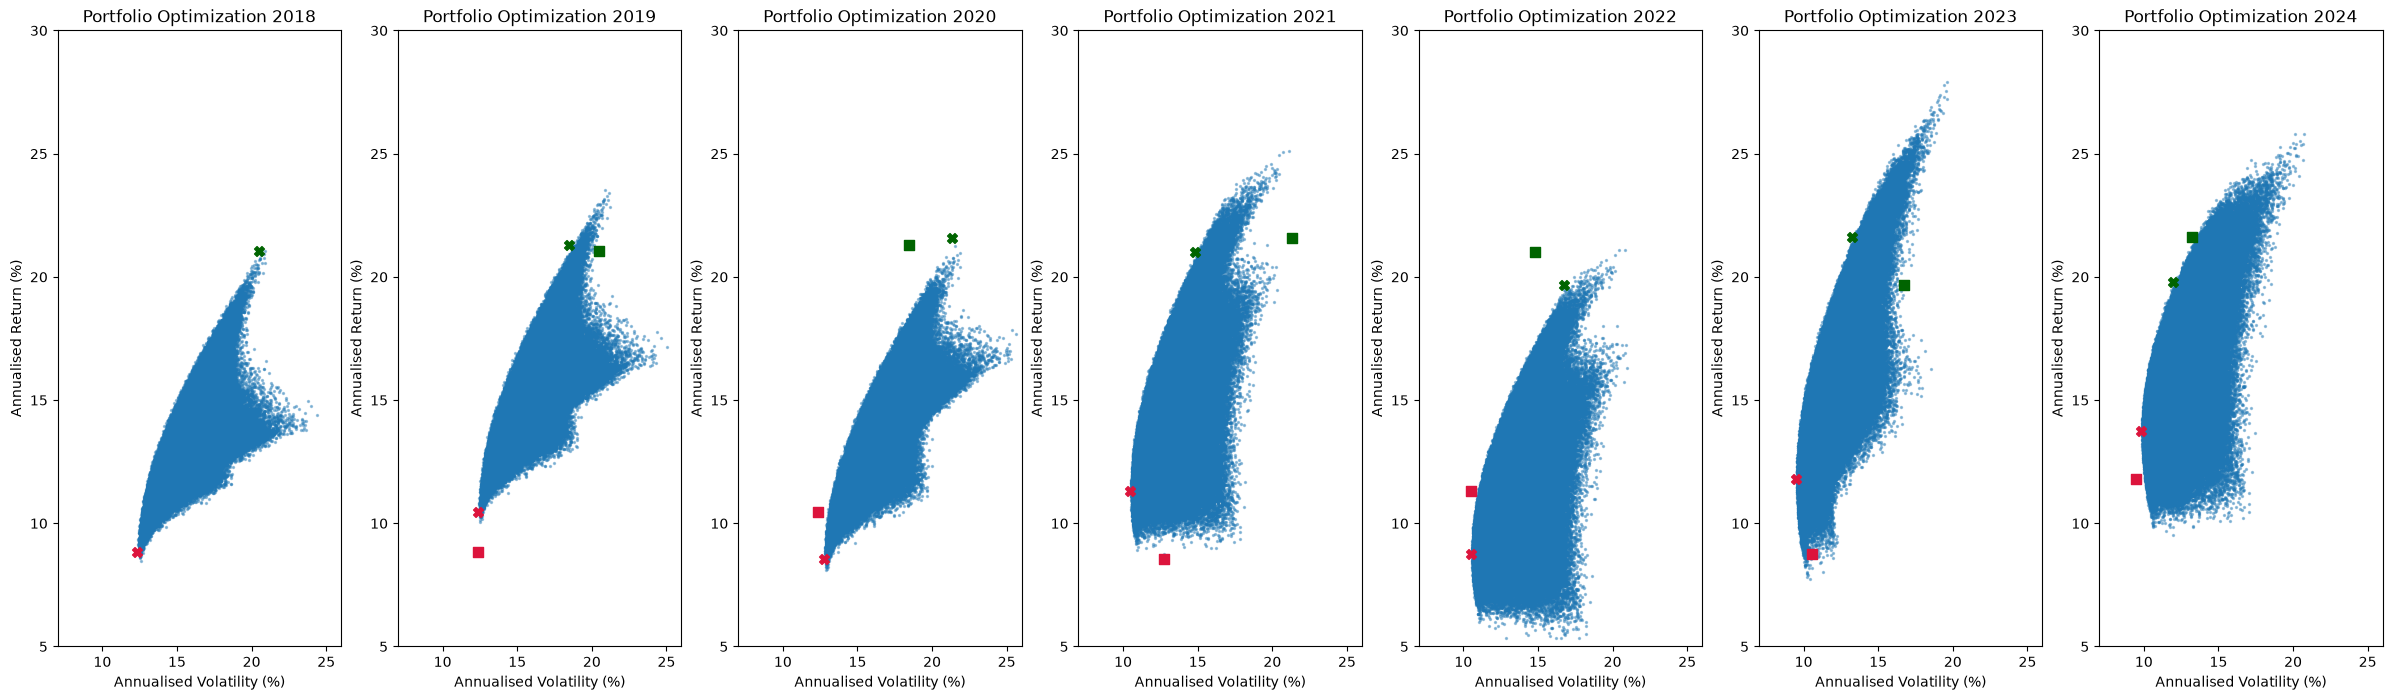

In [64]:
plt.figure(figsize=(30, 8))

for i, year in enumerate(datasets, start = 1):
    plt.subplot(1, 7, i)
    plt.scatter(portfolio_volatility[year] * 100, portfolio_returns[year] * 100, s=2, alpha=0.4)
    plt.scatter(wmv_volatility[year] * 100, wmv_return[year] * 100, s=50, c='crimson', marker='X', label='Minimum Variance Portfolio')
    plt.scatter(wms_volatility[year] * 100, wms_return[year] * 100, s=50, c='darkgreen', marker='X', label='Maximum Sharpe Ratio Portfolio')
    if year - 1 in datasets:
        plt.scatter(wmv_volatility[year - 1] * 100, wmv_return[year - 1] * 100, s=50, c='crimson', marker='s', label='Minimum Variance Portfolio')
        plt.scatter(wms_volatility[year - 1] * 100, wms_return[year - 1] * 100, s=50, c='darkgreen', marker='s', label='Maximum Sharpe Ratio Portfolio')
    plt.xlim(7, 26)
    plt.ylim(5, 30)
    plt.xlabel('Annualised Volatility (%)')
    plt.ylabel('Annualised Return (%)')
    plt.title(f'Portfolio Optimization {year}')

plt.show()

2018 0.7 0.92
